In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.4f}'.format)

RAW = Path(r'/Users/siddharthm/Desktop/churn-prediction/kkbox-churn/data/raw')

In [9]:
train = pd.read_csv(RAW / 'train_v2.csv')
print(f"Training set: {train.shape}")
print(f"\nChurn rate: {train['is_churn'].mean():.2%}")
print(f"Churners:    {train['is_churn'].sum():,}")
print(f"Non-churners:{(train['is_churn']==0).sum():,}")
train.head()

Training set: (970960, 2)

Churn rate: 8.99%
Churners:    87,330
Non-churners:883,630


,msno,is_churn
0,ugx0CjOMzazClkFzU2xasmDZaoIqOUAZPsH1q0teWCg=,1
1,f/NmvEzHfhINFEYZTR05prUdr+E+3+oewvweYz9cCQE=,1
2,zLo9f73nGGT1p21ltZC3ChiRnAVvgibMyazbCxvWPcg=,1
3,8iF/+8HY8lJKFrTc7iR9ZYGCG2Ecrogbc2Vy5YhsfhQ=,1
4,K6fja4+jmoZ5xG6BypqX80Uw/XKpMgrEMdG2edFOxnA=,1


In [10]:
members = pd.read_csv(RAW / 'members_v3.csv')
print(f"Members table: {members.shape}")
print(f"\nMissing values:\n{members.isnull().sum()}")
print(f"\nData types:\n{members.dtypes}")
members.head()

Members table: (6769473, 6)

Missing values:
msno                            0
city                            0
bd                              0
gender                    4429505
registered_via                  0
registration_init_time          0
dtype: int64

Data types:
msno                      object
city                       int64
bd                         int64
gender                    object
registered_via             int64
registration_init_time     int64
dtype: object


,msno,city,bd,gender,registered_via,registration_init_time
0,Rb9UwLQTrxzBVwCB6+bCcSQWZ9JiNLC9dXtM1oEsZA8=,1,0,NaN,11,20110911
1,+tJonkh+O1CA796Fm5X60UMOtB6POHAwPjbTRVl/EuU=,1,0,NaN,7,20110914
2,cV358ssn7a0f7jZOwGNWS07wCKVqxyiImJUX6xcIwKw=,1,0,NaN,11,20110915
3,9bzDeJP6sQodK73K5CBlJ6fgIQzPeLnRl0p5B77XP+g=,1,0,NaN,11,20110915
4,WFLY3s7z4EZsieHCt63XrsdtfTEmJ+2PnnKLH5GY4Tk=,6,32,female,9,20110915


Age distribution (raw):
count   6769473.0000
mean          9.7958
std          17.9259
min       -7168.0000
25%           0.0000
50%           0.0000
75%          21.0000
max        2016.0000
Name: bd, dtype: float64


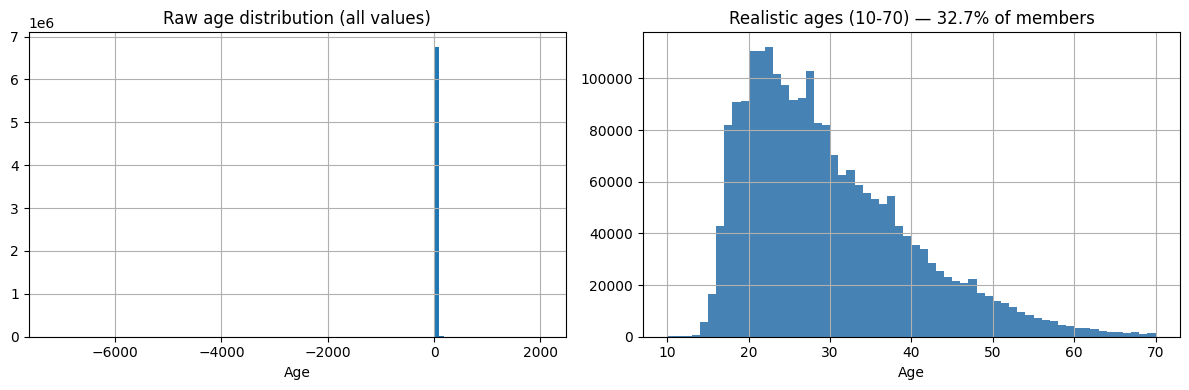


Age = 0: 4,540,215 rows (67.1%)
Age < 0: 274 rows
Age > 70: 12,618 rows


In [11]:
# bd = birth date (actually age)
print("Age distribution (raw):")
print(members['bd'].describe())

# Plot raw age
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
members['bd'].hist(bins=100, ax=axes[0])
axes[0].set_title('Raw age distribution (all values)')
axes[0].set_xlabel('Age')

# Realistic ages only
valid_age = members[(members['bd'] >= 10) & (members['bd'] <= 70)]['bd']
valid_age.hist(bins=60, ax=axes[1], color='steelblue')
axes[1].set_title(f'Realistic ages (10-70) — {len(valid_age)/len(members):.1%} of members')
axes[1].set_xlabel('Age')
plt.tight_layout()
plt.show()

print(f"\nAge = 0: {(members['bd']==0).sum():,} rows ({(members['bd']==0).mean():.1%})")
print(f"Age < 0: {(members['bd']<0).sum():,} rows")
print(f"Age > 70: {(members['bd']>70).sum():,} rows")

In [12]:
print("Gender distribution:")
print(members['gender'].value_counts(dropna=False))
print(f"\nMissing gender: {members['gender'].isnull().mean():.1%}")

print("\nRegistration channel (registered_via):")
print(members['registered_via'].value_counts())

print("\nCity distribution (top 10):")
print(members['city'].value_counts().head(10))

Gender distribution:
gender
NaN       4429505
male      1195355
female    1144613
Name: count, dtype: int64

Missing gender: 65.4%

Registration channel (registered_via):
registered_via
 4     2793213
 3     1643208
 9     1482863
 7      805895
 11      25047
 13       5455
 8        3982
 5        3115
 17       1494
 2        1452
 6        1213
 19        974
 16        888
 14        615
 1          43
 10         10
 18          5
-1           1
Name: count, dtype: int64

City distribution (top 10):
city
1     4804326
5      385069
13     320978
4      246848
22     210407
15     190213
6      135200
14      89940
12      66843
9       47639
Name: count, dtype: int64


In [15]:
transactions = pd.read_csv(RAW / 'transactions_v2.csv')
print(f"Transactions table: {transactions.shape}")
print(f"\nMissing values:\n{transactions.isnull().sum()}")
print(f"\nUnique users: {transactions['msno'].nunique():,}")
transactions.describe()

Transactions table: (1431009, 9)

Missing values:
msno                      0
payment_method_id         0
payment_plan_days         0
plan_list_price           0
actual_amount_paid        0
is_auto_renew             0
transaction_date          0
membership_expire_date    0
is_cancel                 0
dtype: int64

Unique users: 1,197,050


,payment_method_id,payment_plan_days,plan_list_price,actual_amount_paid,is_auto_renew,transaction_date,membership_expire_date,is_cancel
count,1431009.0000,1431009.0000,1431009.0000,1431009.0000,1431009.0000,1431009.0000,1431009.0000,1431009.0000
mean,37.9184,66.0177,281.7870,281.3172,0.7853,20168484.5377,20171100.6821,0.0246
std,4.9648,102.4864,435.1861,435.4200,0.4106,4858.7966,3032.3673,0.1548
min,2.0000,0.0000,0.0000,0.0000,0.0000,20150101.0000,20160419.0000,0.0000
25%,36.0000,30.0000,99.0000,99.0000,1.0000,20170228.0000,20170410.0000,0.0000
50%,40.0000,30.0000,149.0000,149.0000,1.0000,20170311.0000,20170421.0000,0.0000
75%,41.0000,30.0000,149.0000,149.0000,1.0000,20170323.0000,20170501.0000,0.0000
max,41.0000,450.0000,2000.0000,2000.0000,1.0000,20170331.0000,20361015.0000,1.0000


In [16]:
print("Payment plan days (subscription length):")
print(transactions['payment_plan_days'].value_counts().head(10))

print(f"\nAuto-renew rate: {transactions['is_auto_renew'].mean():.2%}")
print(f"Cancellation rate: {transactions['is_cancel'].mean():.2%}")

# Did customer ever pay less than list price?
transactions['discount'] = transactions['plan_list_price'] - transactions['actual_amount_paid']
print(f"\nRows with discount > 0: {(transactions['discount']>0).mean():.2%}")
print(f"Average discount when applied: ${transactions[transactions['discount']>0]['discount'].mean():.2f}")

Payment plan days (subscription length):
payment_plan_days
30     1217998
410      82097
195      28568
180      23900
90       19130
7        12168
395       9753
360       4658
100       4098
365       3838
Name: count, dtype: int64

Auto-renew rate: 78.53%
Cancellation rate: 2.46%

Rows with discount > 0: 0.67%
Average discount when applied: $107.40


In [ ]:
# 18M rows — read in chunks and aggregate counts only, don't load full table
print("Reading user_logs_v2 in chunks")

chunk_stats = []
chunk_size = 500000

for i, chunk in enumerate(pd.read_csv(RAW / 'user_logs_v2.csv', chunksize=chunk_size)):
    chunk_stats.append({
        'rows': len(chunk),
        'unique_users': chunk['msno'].nunique(),
        'date_min': chunk['date'].min(),
        'date_max': chunk['date'].max(),
    })
    if i % 5 == 0:
        print(f"  Chunk {i+1} processed...")

stats_df = pd.DataFrame(chunk_stats)
print(f"\nTotal rows: {stats_df['rows'].sum():,}")
print(f"Date range: {stats_df['date_min'].min()} → {stats_df['date_max'].max()}")
print(f"Avg unique users per chunk: {stats_df['unique_users'].mean():,.0f}")

Reading user_logs_v2 in chunks...
  Chunk 1 processed...
  Chunk 6 processed...
  Chunk 11 processed...
  Chunk 16 processed...
  Chunk 21 processed...
  Chunk 26 processed...
  Chunk 31 processed...
  Chunk 36 processed...

Total rows: 18,396,362
Date range: 20170301 → 20170331
Avg unique users per chunk: 376,103


In [18]:
# How many training users are in each table?
train_users = set(train['msno'])

members_users = set(members['msno'])
txn_users = set(transactions['msno'])

print(f"Training users:                    {len(train_users):,}")
print(f"In members table:    {len(train_users & members_users):,} ({len(train_users & members_users)/len(train_users):.1%})")
print(f"In transactions:     {len(train_users & txn_users):,} ({len(train_users & txn_users)/len(train_users):.1%})")
print(f"\nNot in members:      {len(train_users - members_users):,}")
print(f"Not in transactions: {len(train_users - txn_users):,}")

Training users:                    970,960
In members table:    860,967 (88.7%)
In transactions:     933,578 (96.1%)

Not in members:      109,993
Not in transactions: 37,382
